# Lab 4: Regression Analysis with Regularization Techniques

**Student Name:** Pranavi Balakulla

**Course Title:** MSCS 634
  
**Lab Assignment:** Lab 4 - Regression Analysis with Regularization Techniques

## Step 1: Data Preparation



In [1]:
# Step 1.1: Import libraries and load the dataset

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

diabetes = load_diabetes(as_frame=True)
X = diabetes.data.copy()
y = diabetes.target.copy()

print("Dataset loaded successfully.")
print(f"Number of observations: {X.shape[0]}")
print(f"Number of independent features: {X.shape[1]}")
print(f"Feature names: {list(X.columns)}")
print("Target name: diabetes disease progression")

display(X.head())


Dataset loaded successfully.
Number of observations: 442
Number of independent features: 10
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Target name: diabetes disease progression


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [2]:
# Step 1.2: Inspect structure, data types, and target values

print("Feature data types and non-null counts:")
X.info()

print("\nFirst five target values:")
display(y.head())

print("\nTarget summary statistics:")
display(y.describe())

print("\nFeature summary statistics:")
display(X.describe())


Feature data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
dtypes: float64(10)
memory usage: 34.7 KB

First five target values:


0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64


Target summary statistics:


count    442.000000
mean     152.133484
std       77.093005
min       25.000000
25%       87.000000
50%      140.500000
75%      211.500000
max      346.000000
Name: target, dtype: float64


Feature summary statistics:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.268604e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


In [3]:
# Step 1.3: Check for missing values and duplicate rows

print("Missing values in each feature:")
display(X.isnull().sum().to_frame(name="Missing values"))

print("Missing values in target:", int(y.isnull().sum()))
print("Duplicate feature rows:", int(X.duplicated().sum()))

if X.isnull().values.any() or y.isnull().any():
    print("Missing values were detected. Median imputation will be used inside model pipelines.")
else:
    print("No missing values were detected in the features or target.")


Missing values in each feature:


,Missing values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


Missing values in target: 0
Duplicate feature rows: 0
No missing values were detected in the features or target.


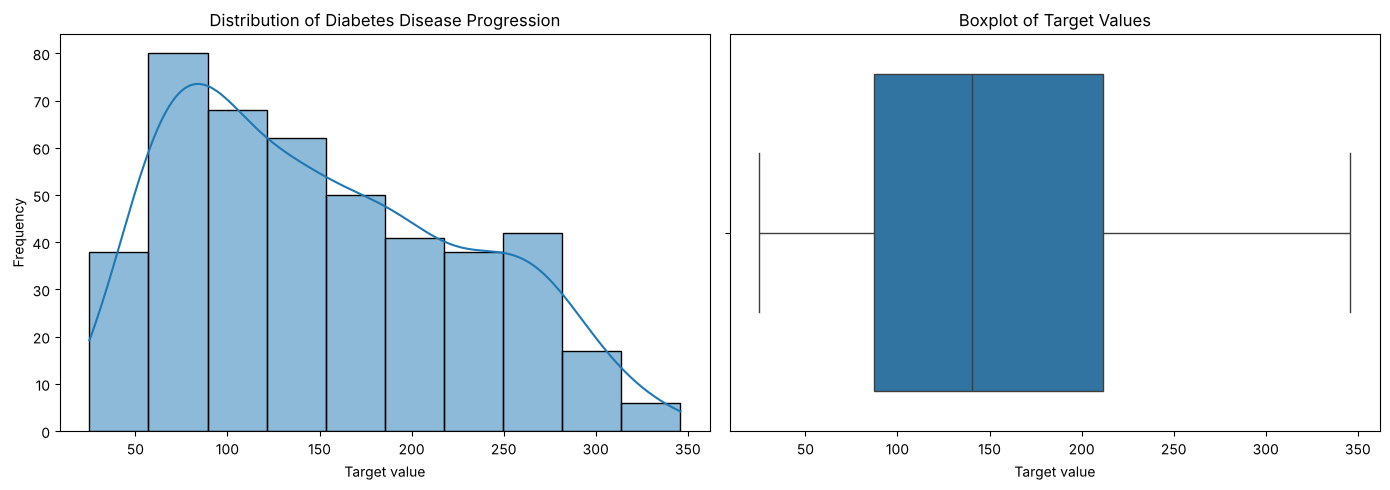

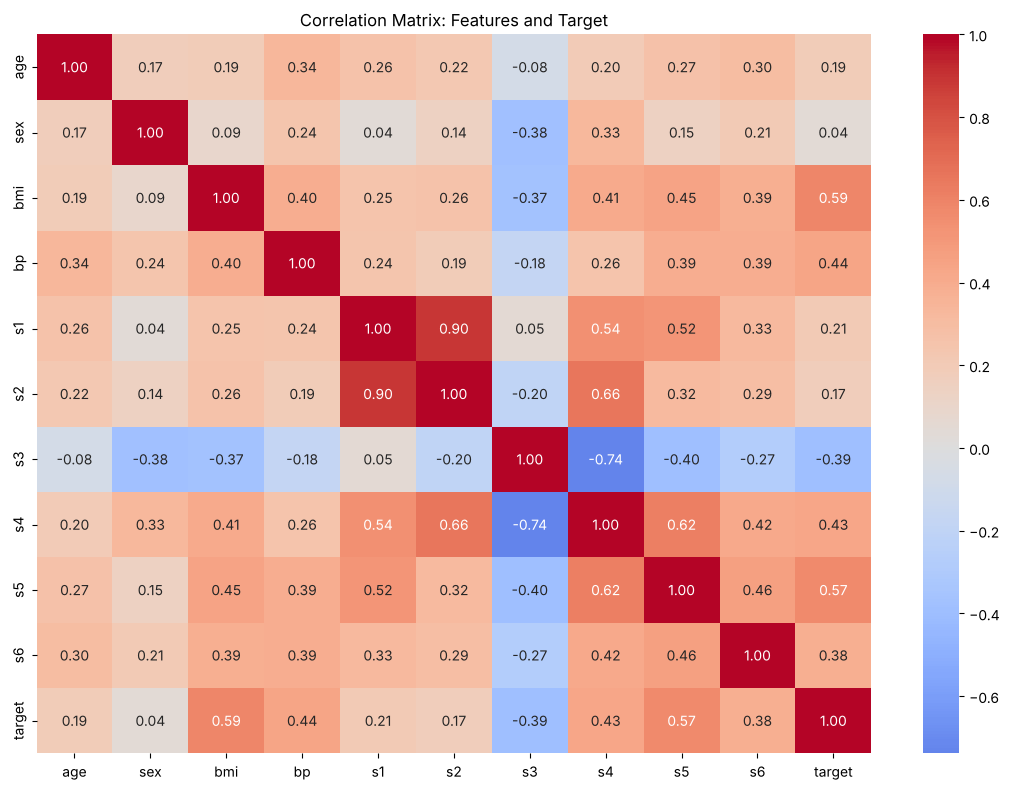

In [4]:
# Step 1.4: Explore the target distribution and feature correlations

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(y, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Diabetes Disease Progression")
axes[0].set_xlabel("Target value")
axes[0].set_ylabel("Frequency")

sns.boxplot(x=y, ax=axes[1])
axes[1].set_title("Boxplot of Target Values")
axes[1].set_xlabel("Target value")

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 8))
correlation_data = X.copy()
correlation_data["target"] = y
sns.heatmap(correlation_data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix: Features and Target")
plt.tight_layout()
plt.show()


### Step 1: Data preparation observations

- **Size and structure:** The dataset contains 442 patient records with 10 numeric features (`age`, `sex`, `bmi`, `bp`, and six blood serum measurements `s1`–`s6`). The target is a quantitative measure of disease progression one year after baseline.
- **Data quality:** There are no missing values in any feature or in the target, and there are no duplicate rows. No cleaning was therefore required. A median imputer is still included in each model pipeline as a safeguard, but it has no effect on this data.
- **Feature scaling:** The features are already mean-centered and scaled by scikit-learn (each column has a mean of about 0 and the same standard deviation of about 0.048), so the raw values are not in clinical units.
- **Target distribution:** The target ranges from 25 to 346 with a mean of about 152. The histogram and boxplot show it is mildly right-skewed (skewness ≈ 0.44), with more patients at lower progression values and no extreme outliers.
- **Correlations with the target:** `bmi` (0.59) and `s5` (0.57) have the strongest positive correlations with disease progression, followed by `bp` (0.44) and `s4` (0.43). `s3` is negatively correlated (−0.39), and `sex` is nearly uncorrelated (0.04). Because `bmi` is the strongest single predictor, it is used for the simple linear and polynomial models.
- **Multicollinearity:** Several features are strongly related to each other, most notably `s1` and `s2` (0.90) and `s3` and `s4` (−0.74). Correlated predictors can make ordinary least-squares coefficients unstable, which is one motivation for testing Ridge and Lasso regularization in Step 5.

## Step 2: Simple Linear Regression

In [5]:
# Step 2.1: Split data and fit Simple Linear Regression

X_simple = X[["bmi"]]

X_train_simple, X_test_simple, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.20, random_state=RANDOM_STATE
)

simple_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

simple_model.fit(X_train_simple, y_train)
y_pred_simple = simple_model.predict(X_test_simple)

print("Simple Linear Regression trained successfully.")
print("Training observations:", len(X_train_simple))
print("Testing observations:", len(X_test_simple))
print("Feature used:", X_simple.columns[0])


Simple Linear Regression trained successfully.
Training observations: 353
Testing observations: 89
Feature used: bmi


In [6]:
# Step 2.2: Define evaluation metrics and evaluate Simple Linear Regression

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_pred)
    }

simple_metrics = regression_metrics(y_test, y_pred_simple)
print("Simple Linear Regression metrics:")
display(pd.DataFrame([simple_metrics], index=["Simple Linear Regression"]).round(4))


Simple Linear Regression metrics:


,MAE,MSE,RMSE,R²
Simple Linear Regression,52.26,4061.8259,63.7325,0.2334


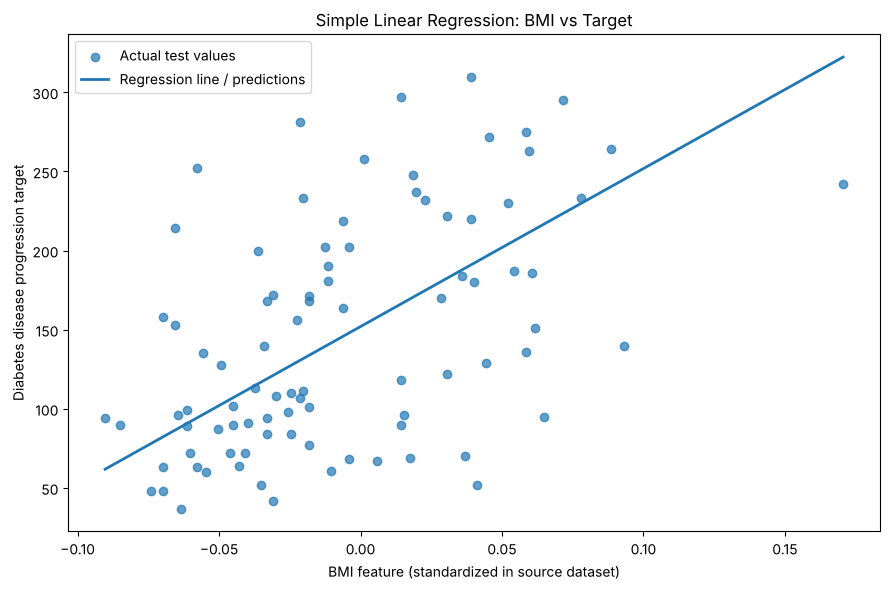

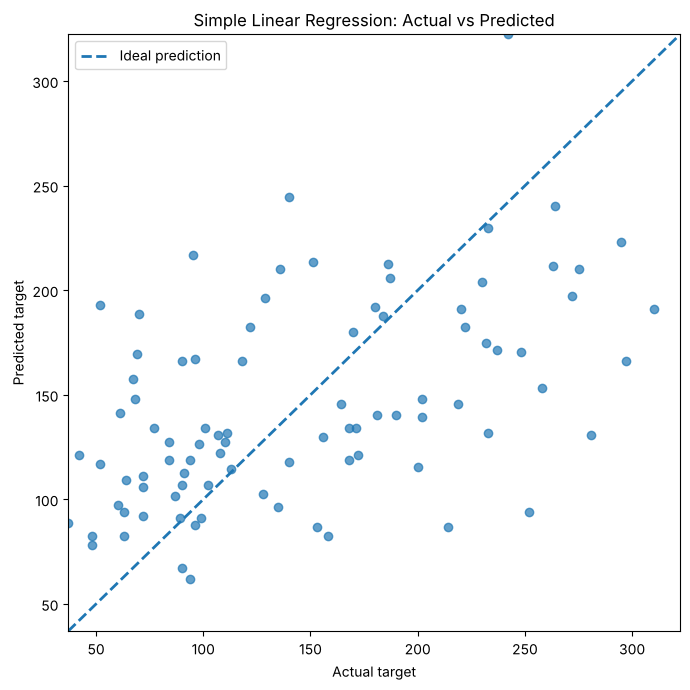

In [7]:
# Step 2.3: Visualize predictions against actual values and the fitted line

plot_df = pd.DataFrame({
    "BMI feature": X_test_simple["bmi"].to_numpy(),
    "Actual target": y_test.to_numpy(),
    "Predicted target": y_pred_simple
}).sort_values("BMI feature")

plt.figure(figsize=(9, 6))
plt.scatter(plot_df["BMI feature"], plot_df["Actual target"], alpha=0.7, label="Actual test values")
plt.plot(plot_df["BMI feature"], plot_df["Predicted target"], linewidth=2, label="Regression line / predictions")
plt.title("Simple Linear Regression: BMI vs Target")
plt.xlabel("BMI feature (standardized in source dataset)")
plt.ylabel("Diabetes disease progression target")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_simple, alpha=0.7)
limits = [
    min(float(y_test.min()), float(np.min(y_pred_simple))),
    max(float(y_test.max()), float(np.max(y_pred_simple)))
]
plt.plot(limits, limits, linestyle="--", linewidth=2, label="Ideal prediction")
plt.xlim(limits)
plt.ylim(limits)
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.legend()
plt.tight_layout()
plt.show()


### Step 2: Simple linear regression interpretation

BMI alone explains about 23% of the variance in disease progression on the test set (R² = 0.233), with a typical error of about 52 points (MAE) and an RMSE of about 64. The fitted line shows a clear positive relationship, meaning higher BMI is associated with faster disease progression, but the points are widely scattered around it. The actual-versus-predicted plot also shows the model overpredicting low values and underpredicting high values, which indicates that one feature is not enough to capture the variation in the target.

## Step 3: Multiple Regression


In [8]:
# Step 3.1: Split the full feature set and fit Multiple Linear Regression

X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

multiple_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("regressor", LinearRegression())
])

multiple_model.fit(X_train_multi, y_train_multi)
y_pred_multi = multiple_model.predict(X_test_multi)

print("Multiple Linear Regression trained successfully.")
print("Number of predictors:", X.shape[1])
print("Training observations:", len(X_train_multi))
print("Testing observations:", len(X_test_multi))


Multiple Linear Regression trained successfully.
Number of predictors: 10
Training observations: 353
Testing observations: 89


In [9]:
# Step 3.2: Evaluate Multiple Regression

multi_metrics = regression_metrics(y_test_multi, y_pred_multi)
display(pd.DataFrame([multi_metrics], index=["Multiple Linear Regression"]).round(4))


,MAE,MSE,RMSE,R²
Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526


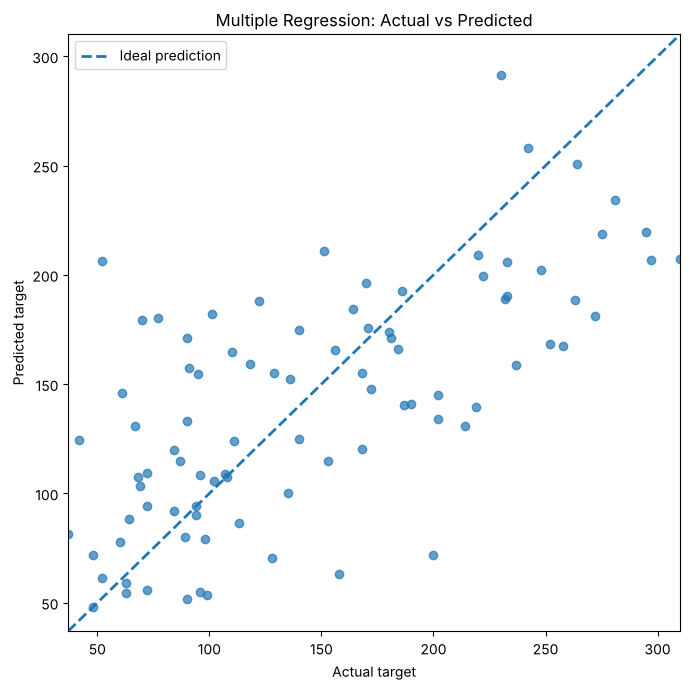

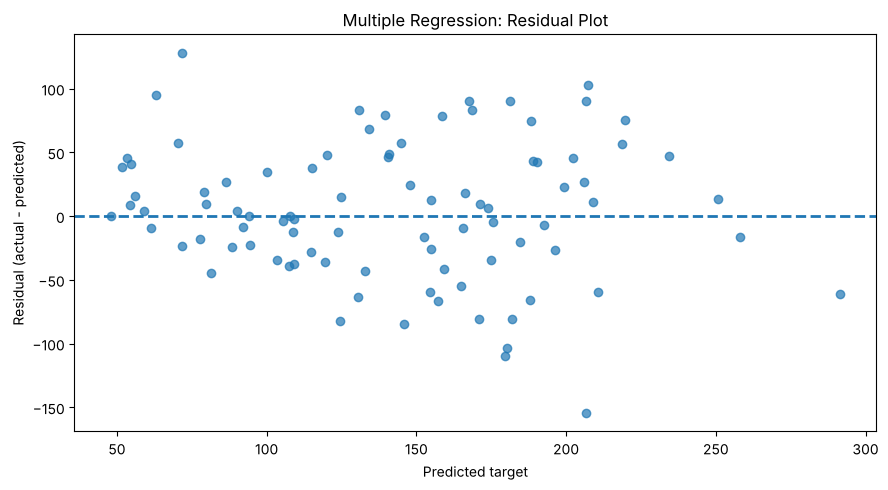

In [10]:
# Step 3.3: Visualize actual versus predicted target values

plt.figure(figsize=(7, 7))
plt.scatter(y_test_multi, y_pred_multi, alpha=0.7)
limits = [
    min(float(y_test_multi.min()), float(np.min(y_pred_multi))),
    max(float(y_test_multi.max()), float(np.max(y_pred_multi)))
]
plt.plot(limits, limits, linestyle="--", linewidth=2, label="Ideal prediction")
plt.xlim(limits)
plt.ylim(limits)
plt.title("Multiple Regression: Actual vs Predicted")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.legend()
plt.tight_layout()
plt.show()

residuals_multi = y_test_multi.to_numpy() - y_pred_multi
plt.figure(figsize=(9, 5))
plt.scatter(y_pred_multi, residuals_multi, alpha=0.7)
plt.axhline(0, linestyle="--", linewidth=2)
plt.title("Multiple Regression: Residual Plot")
plt.xlabel("Predicted target")
plt.ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()


### Step 3: Multiple regression interpretation

Using all 10 features raises test R² from 0.233 to 0.453 and lowers RMSE from 63.73 to 53.85 compared with the BMI-only model, so the additional health measurements nearly double the share of variance explained. The actual-versus-predicted plot follows the ideal line more closely than in Step 2, although predictions are still compressed toward the middle of the range. The residual plot shows residuals scattered around zero without a strong curved pattern, which supports using a linear model, but the spread of errors remains wide.

## Step 4: Polynomial Regression

In [11]:
# Step 4.1: Train Polynomial Regression models with different degrees

X_train_poly, X_test_poly, y_train_poly, y_test_poly = train_test_split(
    X[["bmi"]], y, test_size=0.20, random_state=RANDOM_STATE
)

polynomial_degrees = [1, 2, 3, 5, 10]
polynomial_models = {}
polynomial_predictions = {}
polynomial_rows = []

for degree in polynomial_degrees:
    model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])
    model.fit(X_train_poly, y_train_poly)
    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    polynomial_models[degree] = model
    polynomial_predictions[degree] = test_pred

    train_m = regression_metrics(y_train_poly, train_pred)
    test_m = regression_metrics(y_test_poly, test_pred)

    polynomial_rows.append({
        "Degree": degree,
        "Train MAE": train_m["MAE"],
        "Test MAE": test_m["MAE"],
        "Train RMSE": train_m["RMSE"],
        "Test RMSE": test_m["RMSE"],
        "Train R²": train_m["R²"],
        "Test R²": test_m["R²"]
    })

polynomial_results = pd.DataFrame(polynomial_rows).set_index("Degree")
display(polynomial_results.round(4))


,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R²,Test R²
Degree,,,,,,
1,51.3797,52.2600,62.0815,63.7325,0.3657,0.2334
2,51.3266,52.3839,62.0430,63.9142,0.3665,0.2290
3,51.2801,52.1814,62.0359,63.7530,0.3667,0.2329
5,51.0087,51.8846,61.8366,63.9206,0.3707,0.2288
10,50.4517,52.9589,61.0296,65.6927,0.3870,0.1855


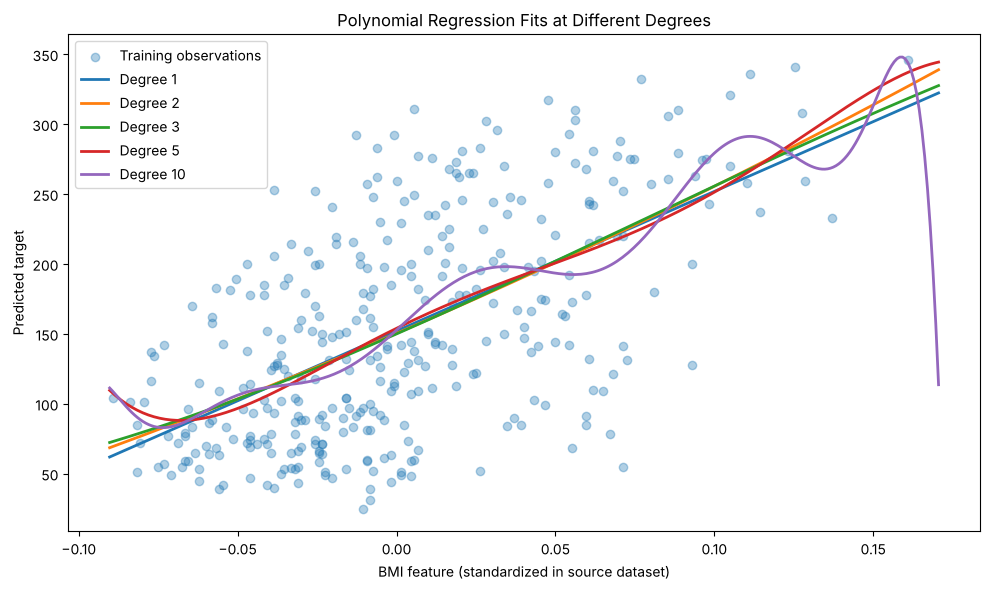

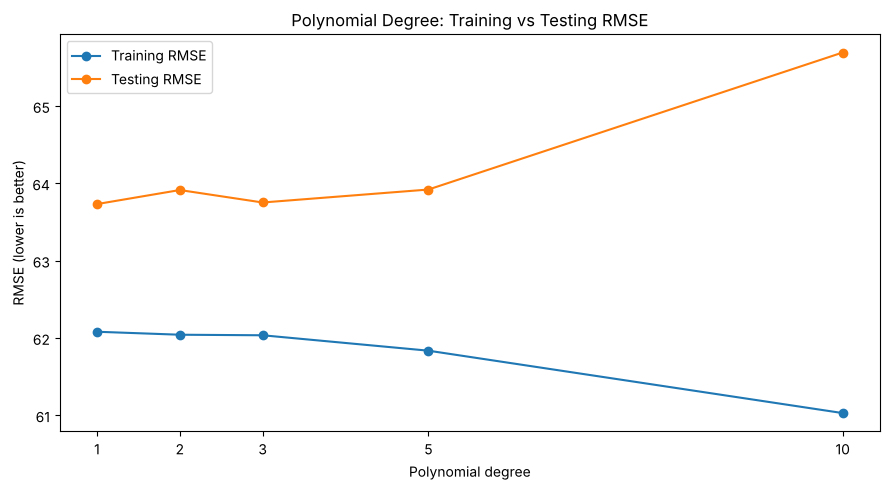

In [12]:
# Step 4.2: Visualize polynomial fits across the feature range

bmi_grid = pd.DataFrame({
    "bmi": np.linspace(float(X["bmi"].min()), float(X["bmi"].max()), 300)
})

plt.figure(figsize=(10, 6))
plt.scatter(X_train_poly["bmi"], y_train_poly, alpha=0.35, label="Training observations")

for degree in polynomial_degrees:
    grid_predictions = polynomial_models[degree].predict(bmi_grid)
    plt.plot(bmi_grid["bmi"], grid_predictions, linewidth=2, label=f"Degree {degree}")

plt.title("Polynomial Regression Fits at Different Degrees")
plt.xlabel("BMI feature (standardized in source dataset)")
plt.ylabel("Predicted target")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(polynomial_results.index, polynomial_results["Train RMSE"], marker="o", label="Training RMSE")
plt.plot(polynomial_results.index, polynomial_results["Test RMSE"], marker="o", label="Testing RMSE")
plt.title("Polynomial Degree: Training vs Testing RMSE")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (lower is better)")
plt.xticks(polynomial_degrees)
plt.legend()
plt.tight_layout()
plt.show()


### Step 4: Interpretation of polynomial degree

- **Training error keeps falling:** As the degree increases from 1 to 10, training RMSE falls steadily from 62.08 to 61.03 and training R² rises from 0.366 to 0.387. A more flexible curve can always fit the training points at least as closely.
- **Testing error does not improve:** Test RMSE stays roughly flat between degrees 1 and 5 (63.73 to 63.92), then rises sharply to 65.69 at degree 10, where test R² drops to 0.186. The gap between training and testing performance widens as the degree grows. This is the signature of **overfitting**: the degree-10 curve bends to follow noise in the training sample, and the fit plot shows it wiggling through the middle of the BMI range and plunging sharply at the highest BMI values, where there are very few observations.
- **Underfitting:** All of the BMI-only polynomial models explain only about 23% of the variance on the test set and about 37% on the training set. Both errors are high, which means a single feature cannot capture enough of the variation in disease progression. This is the **underfitting** side of the bias–variance trade-off: the model is too simple (in terms of the information it uses) rather than too flexible. Degree 1 is the simplest model and has the highest training error of the group.
- **Why extra degrees do not help:** The relationship between BMI and disease progression is close to linear, so the additional polynomial terms add little real signal and mostly fit noise. Degree 1 (equivalent to the simple linear regression in Step 2) and degree 3 perform best on the test set. Polynomial models also remain well behind the multiple regression model (test R² ≈ 0.45), which shows that adding informative features helped far more than adding curvature to one feature.

## Step 5: Regularization with Ridge and Lasso Regression


In [13]:
# Step 5.1: Fit Ridge and Lasso models over several alpha values

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# The grid spans weak to strong regularization; 50 and 100 were added so the best Ridge alpha is not at the edge of the grid
alpha_values = [0.001, 0.01, 0.1, 1.0, 10.0, 50.0, 100.0]
regularized_models = {}
regularized_predictions = {}
regularized_rows = []

for alpha in alpha_values:
    ridge_model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=alpha))
    ])
    ridge_model.fit(X_train_reg, y_train_reg)
    ridge_pred = ridge_model.predict(X_test_reg)
    ridge_train_pred = ridge_model.predict(X_train_reg)

    regularized_models[("Ridge", alpha)] = ridge_model
    regularized_predictions[("Ridge", alpha)] = ridge_pred

    ridge_test_metrics = regression_metrics(y_test_reg, ridge_pred)
    ridge_train_metrics = regression_metrics(y_train_reg, ridge_train_pred)
    regularized_rows.append({
        "Model": "Ridge",
        "Alpha": alpha,
        "Train MAE": ridge_train_metrics["MAE"],
        "Test MAE": ridge_test_metrics["MAE"],
        "Test MSE": ridge_test_metrics["MSE"],
        "Test RMSE": ridge_test_metrics["RMSE"],
        "Test R²": ridge_test_metrics["R²"]
    })

    lasso_model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Lasso(alpha=alpha, max_iter=50000))
    ])
    lasso_model.fit(X_train_reg, y_train_reg)
    lasso_pred = lasso_model.predict(X_test_reg)
    lasso_train_pred = lasso_model.predict(X_train_reg)

    regularized_models[("Lasso", alpha)] = lasso_model
    regularized_predictions[("Lasso", alpha)] = lasso_pred

    lasso_test_metrics = regression_metrics(y_test_reg, lasso_pred)
    lasso_train_metrics = regression_metrics(y_train_reg, lasso_train_pred)
    regularized_rows.append({
        "Model": "Lasso",
        "Alpha": alpha,
        "Train MAE": lasso_train_metrics["MAE"],
        "Test MAE": lasso_test_metrics["MAE"],
        "Test MSE": lasso_test_metrics["MSE"],
        "Test RMSE": lasso_test_metrics["RMSE"],
        "Test R²": lasso_test_metrics["R²"]
    })

regularization_results = pd.DataFrame(regularized_rows)
display(regularization_results.round(4))


,Model,Alpha,Train MAE,Test MAE,Test MSE,Test RMSE,Test R²
0,Ridge,0.001,43.4835,42.7941,2900.1817,53.8533,0.4526
1,Lasso,0.001,43.4836,42.7941,2900.0084,53.8517,0.4526
2,Ridge,0.010,43.4835,42.7942,2900.0751,53.8523,0.4526
3,Lasso,0.010,43.4841,42.7950,2898.3680,53.8365,0.4529
4,Ridge,0.100,43.4837,42.7962,2899.0546,53.8429,0.4528
5,Lasso,0.100,43.5157,42.8052,2884.6243,53.7087,0.4555
6,Ridge,1.000,43.4947,42.8120,2892.0146,53.7775,0.4541
7,Lasso,1.000,43.8391,42.8030,2824.5681,53.1467,0.4669
8,Ridge,10.000,43.6385,42.8568,2875.7787,53.6263,0.4572
9,Lasso,10.000,47.6455,44.7646,2933.8347,54.1649,0.4463


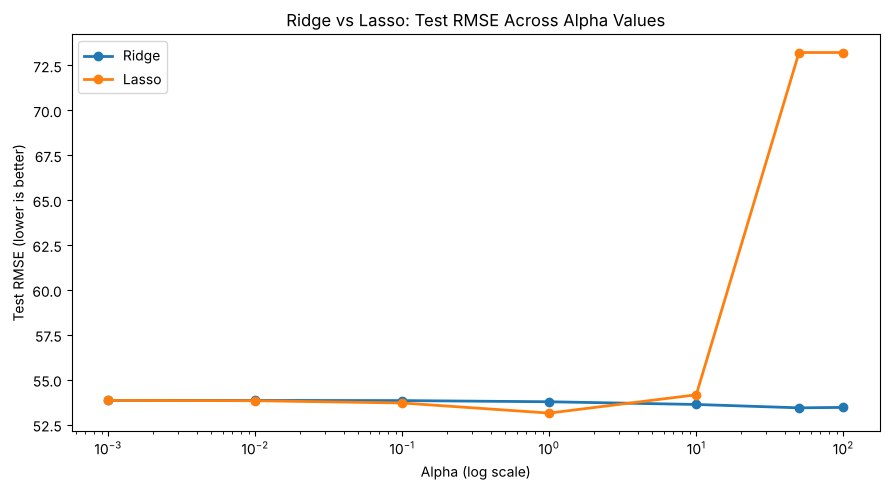

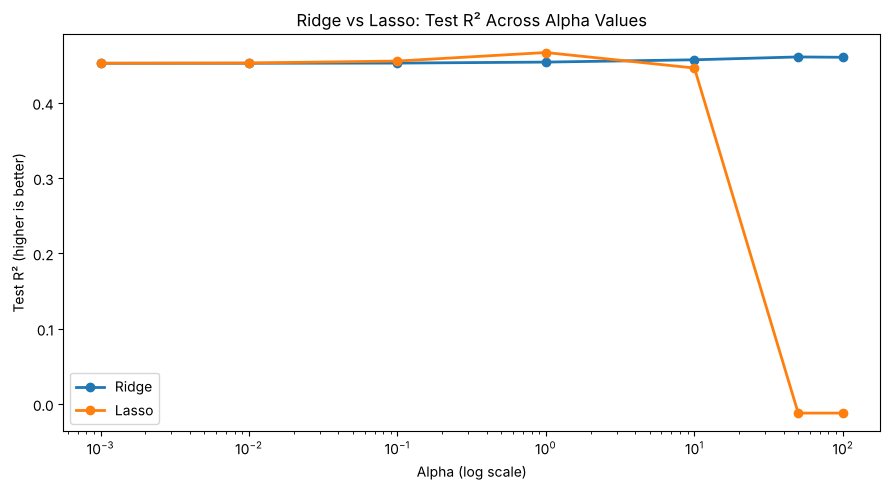

In [14]:
# Step 5.2: Compare Ridge and Lasso test RMSE across alpha values

plt.figure(figsize=(9, 5))

for model_name in ["Ridge", "Lasso"]:
    subset = regularization_results[regularization_results["Model"] == model_name].sort_values("Alpha")
    plt.plot(subset["Alpha"], subset["Test RMSE"], marker="o", linewidth=2, label=model_name)

plt.xscale("log")
plt.title("Ridge vs Lasso: Test RMSE Across Alpha Values")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Test RMSE (lower is better)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
for model_name in ["Ridge", "Lasso"]:
    subset = regularization_results[regularization_results["Model"] == model_name].sort_values("Alpha")
    plt.plot(subset["Alpha"], subset["Test R²"], marker="o", linewidth=2, label=model_name)

plt.xscale("log")
plt.title("Ridge vs Lasso: Test R² Across Alpha Values")
plt.xlabel("Alpha (log scale)")
plt.ylabel("Test R² (higher is better)")
plt.legend()
plt.tight_layout()
plt.show()


Best alpha per method based on the held-out test RMSE (descriptive comparison):


,Model,Alpha,Test RMSE,Test R²
7,Lasso,1.0,53.1467,0.4669
10,Ridge,50.0,53.4388,0.4610


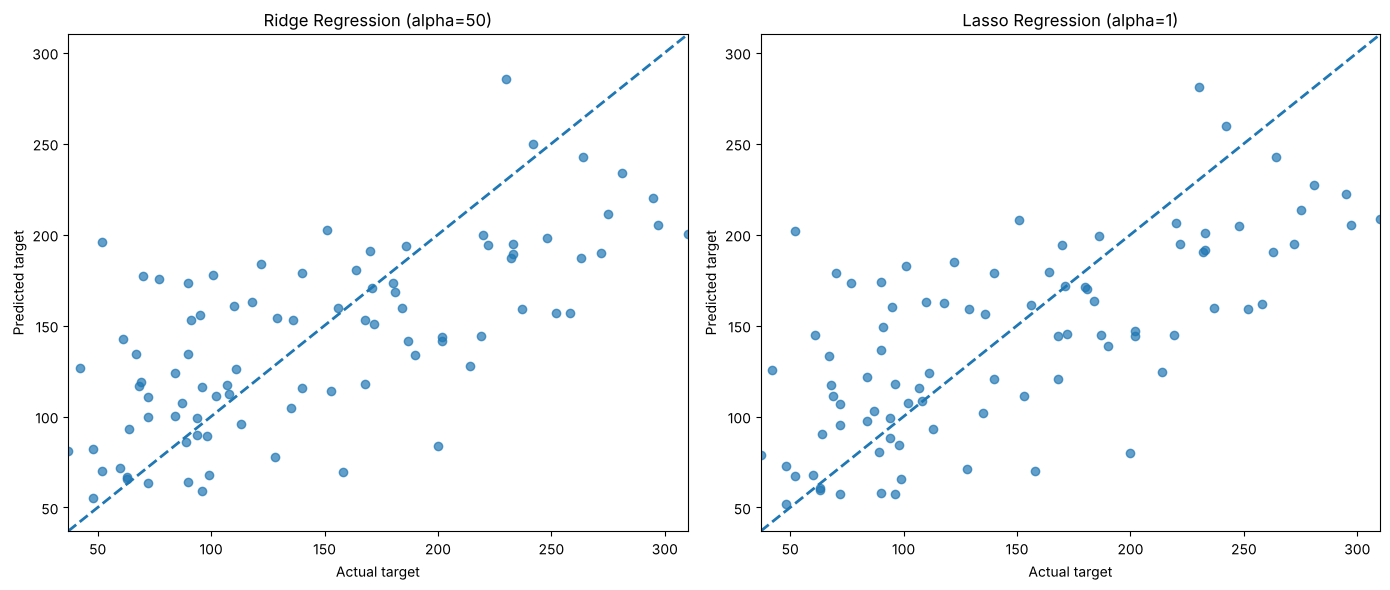

In [15]:
# Step 5.3: Visualize actual versus predicted values for the best alpha per method

best_alpha_by_method = (
    regularization_results.loc[
        regularization_results.groupby("Model")["Test RMSE"].idxmin(),
        ["Model", "Alpha", "Test RMSE", "Test R²"]
    ].sort_values("Model")
)

print("Best alpha per method based on the held-out test RMSE (descriptive comparison):")
display(best_alpha_by_method.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, model_name in zip(axes, ["Ridge", "Lasso"]):
    best_row = best_alpha_by_method[best_alpha_by_method["Model"] == model_name].iloc[0]
    alpha = float(best_row["Alpha"])
    pred = regularized_predictions[(model_name, alpha)]

    ax.scatter(y_test_reg, pred, alpha=0.7)
    limits = [
        min(float(y_test_reg.min()), float(np.min(pred))),
        max(float(y_test_reg.max()), float(np.max(pred)))
    ]
    ax.plot(limits, limits, linestyle="--", linewidth=2)
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_title(f"{model_name} Regression (alpha={alpha:g})")
    ax.set_xlabel("Actual target")
    ax.set_ylabel("Predicted target")

plt.tight_layout()
plt.show()


In [16]:
# Step 5.4: Inspect coefficient shrinkage and the number of nonzero Lasso coefficients

coefficient_rows = []

for model_name in ["Ridge", "Lasso"]:
    for alpha in alpha_values:
        pipeline = regularized_models[(model_name, alpha)]
        coefficients = pipeline.named_steps["regressor"].coef_
        coefficient_rows.append({
            "Model": model_name,
            "Alpha": alpha,
            "Sum of absolute coefficients": float(np.abs(coefficients).sum()),
            "Number of nonzero coefficients": int(np.count_nonzero(np.abs(coefficients) > 1e-8))
        })

coefficient_results = pd.DataFrame(coefficient_rows)
display(coefficient_results.round(4))


,Model,Alpha,Sum of absolute coefficients,Number of nonzero coefficients
0,Ridge,0.001,183.0848,10
1,Ridge,0.010,182.7722,10
2,Ridge,0.100,179.7379,10
3,Ridge,1.000,156.4183,10
4,Ridge,10.000,108.7037,10
5,Ridge,50.000,97.8170,10
6,Ridge,100.000,89.6454,10
7,Lasso,0.001,182.6976,10
8,Lasso,0.010,178.8990,10
9,Lasso,0.100,140.9604,10


### Step 5: How alpha affects Ridge and Lasso

- **What alpha does:** Alpha sets the strength of the penalty on the size of the coefficients. A higher alpha forces the model to keep coefficients smaller, trading a little extra bias for lower variance.
- **Very small alpha ≈ ordinary linear regression:** At alpha = 0.001 the penalty is negligible, so both Ridge and Lasso reproduce the Multiple Linear Regression results almost exactly (test MAE 42.7941, R² 0.4526).
- **Ridge (L2 penalty) shrinks but keeps every feature:** As alpha rises from 0.001 to 100, the sum of absolute Ridge coefficients falls from about 183 to about 90, but all 10 coefficients stay nonzero. Ridge spreads weight across correlated features such as `s1` and `s2` instead of choosing between them. Its test RMSE improves gradually and is lowest at alpha = 50 (53.44, R² 0.461), then begins to rise slightly at alpha = 100, so the best value is now inside the grid rather than at its edge.
- **Lasso (L1 penalty) shrinks and selects features:** Lasso can set coefficients exactly to zero. At alpha = 1 it removes `s2` (9 nonzero coefficients) and reaches the best test RMSE of all models (53.15, R² 0.467). At alpha = 10 it keeps only 4 features (`bmi`, `bp`, `s3`, `s5`), and performance begins to decline.
- **Too much regularization causes underfitting:** At alpha = 50 and 100, Lasso sets every coefficient to zero, so it predicts the training mean for every patient and test R² falls to about −0.01. This is the extreme case of underfitting. Ridge never removes features, so it degrades much more slowly at the same alpha values.
- **Ridge vs Lasso in practice:** The two best models perform similarly, which suggests the dataset has a modest amount of redundancy. Lasso has the advantage of producing a simpler, more interpretable model by dropping a redundant feature, while Ridge is more forgiving of a poorly chosen alpha.
- **Limitation:** The best alpha was chosen by comparing test-set scores, so these test scores are slightly optimistic. In practice, alpha should be chosen with cross-validation on the training data (for example, `RidgeCV` or `LassoCV`) and the test set used only once at the end.

## Step 6: Model Comparison and Analysis


In [17]:
# Step 6.1: Build a common comparison table

comparison_rows = []

comparison_rows.append({
    "Model": "Simple Linear Regression (BMI)",
    **regression_metrics(y_test, y_pred_simple)
})

comparison_rows.append({
    "Model": "Multiple Linear Regression",
    **regression_metrics(y_test_multi, y_pred_multi)
})

for degree in polynomial_degrees:
    comparison_rows.append({
        "Model": f"Polynomial Regression (degree {degree})",
        **regression_metrics(y_test_poly, polynomial_predictions[degree])
    })

for model_name in ["Ridge", "Lasso"]:
    best_row = best_alpha_by_method[best_alpha_by_method["Model"] == model_name].iloc[0]
    alpha = float(best_row["Alpha"])
    pred = regularized_predictions[(model_name, alpha)]
    comparison_rows.append({
        "Model": f"{model_name} Regression (alpha={alpha:g})",
        **regression_metrics(y_test_reg, pred)
    })

comparison_table = pd.DataFrame(comparison_rows).set_index("Model")
comparison_table = comparison_table.sort_values("RMSE")
display(comparison_table.round(4))


,MAE,MSE,RMSE,R²
Model,,,,
Lasso Regression (alpha=1),42.8030,2824.5681,53.1467,0.4669
Ridge Regression (alpha=50),43.0319,2855.7081,53.4388,0.4610
Multiple Linear Regression,42.7941,2900.1936,53.8534,0.4526
Polynomial Regression (degree 1),52.2600,4061.8259,63.7325,0.2334
Simple Linear Regression (BMI),52.2600,4061.8259,63.7325,0.2334
Polynomial Regression (degree 3),52.1814,4064.4434,63.7530,0.2329
Polynomial Regression (degree 2),52.3839,4085.0255,63.9142,0.2290
Polynomial Regression (degree 5),51.8846,4085.8456,63.9206,0.2288
Polynomial Regression (degree 10),52.9589,4315.5331,65.6927,0.1855


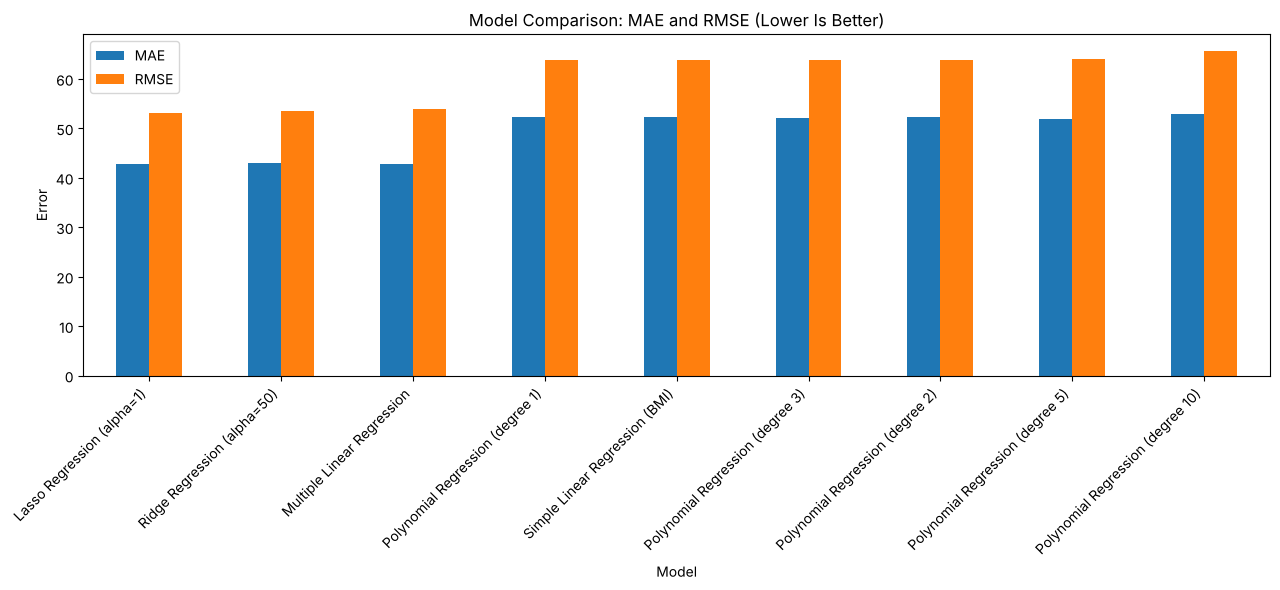

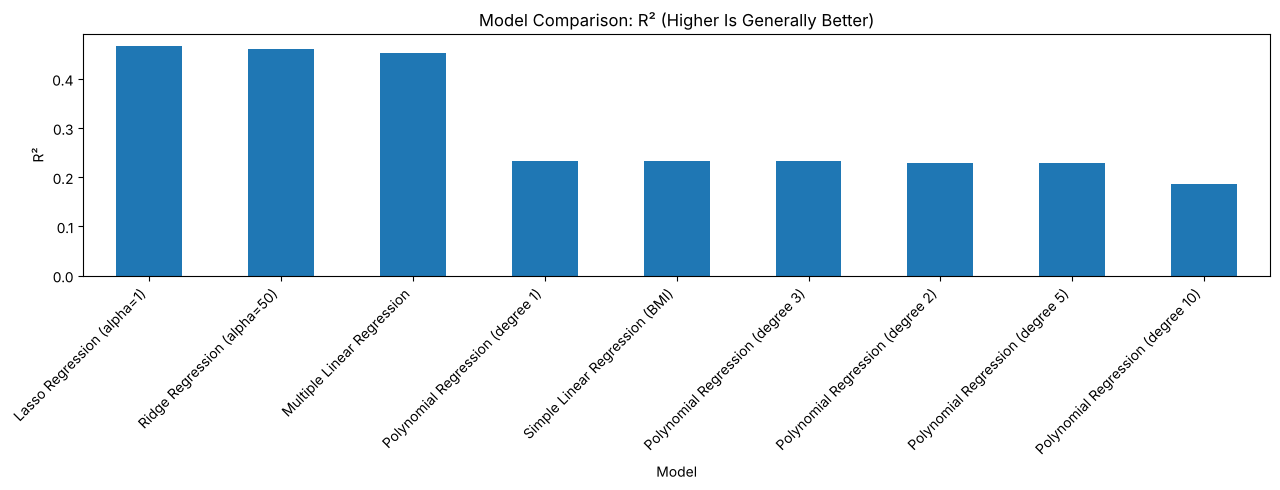

In [18]:
# Step 6.2: Visualize model comparison

comparison_table[["MAE", "RMSE"]].sort_values("RMSE").plot(
    kind="bar", figsize=(13, 6)
)
plt.title("Model Comparison: MAE and RMSE (Lower Is Better)")
plt.ylabel("Error")
plt.xlabel("Model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

comparison_table["R²"].sort_values(ascending=False).plot(
    kind="bar", figsize=(13, 5)
)
plt.title("Model Comparison: R² (Higher Is Generally Better)")
plt.ylabel("R²")
plt.xlabel("Model")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [19]:
# Step 6.3: Automatically summarize the observed comparison results

best_rmse_model = comparison_table["RMSE"].idxmin()
best_mae_model = comparison_table["MAE"].idxmin()
best_r2_model = comparison_table["R²"].idxmax()

print("RESULTS-BASED SUMMARY")
print("---------------------")
print(f"Lowest test RMSE: {best_rmse_model} (RMSE = {comparison_table.loc[best_rmse_model, 'RMSE']:.4f})")
print(f"Lowest test MAE:  {best_mae_model} (MAE = {comparison_table.loc[best_mae_model, 'MAE']:.4f})")
print(f"Highest test R²:  {best_r2_model} (R² = {comparison_table.loc[best_r2_model, 'R²']:.4f})")

RESULTS-BASED SUMMARY
---------------------
Lowest test RMSE: Lasso Regression (alpha=1) (RMSE = 53.1467)
Lowest test MAE:  Multiple Linear Regression (MAE = 42.7941)
Highest test R²:  Lasso Regression (alpha=1) (R² = 0.4669)


### Step 6.4: Discussion

---



The regression models were evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (\\(R^2\\)) to compare their predictive performance on the Diabetes dataset. Lower MAE, MSE, and RMSE values indicate smaller prediction errors, while a higher \\(R^2\\) indicates that the model explains more variation in the target variable. Among the models tested, Lasso Regression with alpha = 1 achieved the lowest RMSE of 53.1467 and the highest \\(R^2\\) of 0.4669. Multiple Linear Regression achieved the lowest MAE of 42.7941, while Ridge Regression with alpha = 50 recorded an RMSE of 53.4388 and an \\(R^2\\) of 0.4610. These results indicate that Lasso Regression provided the strongest overall performance based on RMSE and \\(R^2\\), although Multiple Linear Regression had the smallest average absolute prediction error.

The comparison between Ridge and Lasso Regression showed that regularization improved predictive performance compared with the standard Multiple Linear Regression model. Multiple Linear Regression recorded an RMSE of 53.8534 and an \\(R^2\\) of 0.4526, whereas Lasso Regression with alpha = 1 reduced the RMSE to 53.1467 and increased \\(R^2\\) to 0.4669. Ridge Regression with alpha = 50 also performed better than Multiple Linear Regression, achieving an RMSE of 53.4388. Regularization helps control model complexity by penalizing large coefficients, which can reduce overfitting and improve generalization to unseen data. However, the results do not prove that overfitting was completely eliminated; they show that the regularized models performed better on the test data according to the reported metrics.

Polynomial Regression produced weaker results than the linear and regularized regression models. Polynomial models with degrees 1, 2, 3, 5, and 10 recorded test RMSE values of 63.7325, 63.9142, 63.7530, 63.9206, and 65.6927, respectively. Their \\(R^2\\) values were also lower, ranging from 0.1855 to 0.2334, compared with the regularized models' values of approximately 0.45 to 0.47. The degree-10 polynomial model had the highest test RMSE and the lowest \\(R^2\\) among the models compared, indicating that increasing polynomial complexity did not improve predictive accuracy. The training-versus-testing RMSE graph also shows training error decreasing as polynomial degree increases while testing error rises at degree 10. This pattern suggests overfitting at higher polynomial complexity, where the model fits the training data more closely but performs worse on unseen observations.

The results provide useful insights into the Diabetes dataset. The relatively stronger performance of the linear and regularized models suggests that simpler relationships captured by these models were more effective for predicting the target variable than the higher-degree polynomial transformations tested. Nevertheless, the best \\(R^2\\) value of 0.4669 indicates that the strongest model explained approximately 46.69% of the variation in the target variable, leaving substantial variation unexplained. This suggests that the available predictors may not capture every factor associated with the target and that prediction errors remain meaningful. Overall, Lasso Regression with alpha = 1 is the preferred model based on the lowest RMSE and highest \\(R^2\\), while Multiple Linear Regression remains competitive based on MAE. Future improvements could include cross-validation, systematic hyperparameter tuning, feature selection, and testing additional models to determine whether predictive performance can be improved further.